In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
DATA_DIR = "../data/troupe/TLS"

In [4]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [5]:
t_id = 11
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	138
Total number of nodes:	275
Rooted:	Yes
Most distant node:	AGATGCTGTGAGATCG-1
Max. distance:	0.993355


In [6]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i + 1
    
    G.add_node(0, name="root", dist=0.0, is_leaf=False)

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, length=node.dist)
        else:
            G.add_edge(0, node_id, length=node.dist)

    G.graph["root"] = 0

    return G

In [7]:
T = ete_to_nx(t)
T

In [8]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False}, 1: {'name': '', 'dist': 0.0066449770759561275, 'is_leaf': False}, 2: {'name': 'node_232', 'dist': 0.046374793170274466, 'is_leaf': False}, 3: {'name': 'node_238', 'dist': 0.006644976998620287, 'is_leaf': False}, 4: {'name': 'node_244', 'dist': 0.09508556807828979, 'is_leaf': False}, 5: {'name': 'node_250', 'dist': 0.0967763410451998, 'is_leaf': False}, 6: {'name': 'node_256', 'dist': 0.5932419640265092, 'is_leaf': False}, 7: {'name': 'CATAAGCAGGCACTAG-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero'}, 8: {'name': 'CGCATAAGTAATCAGA-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero'}, 9: {'name': 'node_251', 'dist': 0.44533857256503545, 'is_leaf': False}, 10: {'name': 'AACCTTTGTGATGAAT-1', 'dist': 0.29648979312418045, 'is_leaf': True, 'state': 'NeuralTube', 'state_coarse': 'Neu

In [9]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'length': 0.0066449770759561275}), (1, 2, {'length': 0.046374793170274466}), (1, 29, {'length': 0.0066449778055180445}), (2, 3, {'length': 0.006644976998620287}), (2, 24, {'length': 0.006644977114757893}), (3, 4, {'length': 0.09508556807828979}), (3, 19, {'length': 0.543913516019353}), (4, 5, {'length': 0.0967763410451998}), (4, 14, {'length': 0.21941044941119803}), (5, 6, {'length': 0.5932419640265092}), (5, 9, {'length': 0.44533857256503545}), (6, 7, {'length': 0.14858640166270679}), (6, 8, {'length': 0.14858640166270679}), (9, 10, {'length': 0.29648979312418045}), (9, 11, {'length': 0.006644980794975847}), (11, 12, {'length': 0.2898448123292046}), (11, 13, {'length': 0.2898448123292046}), (14, 15, {'length': 0.06754991101792483}), (14, 18, {'length': 0.6191942573832001}), (15, 16, {'length': 0.5516443463652753}), (15, 17, {'length': 0.5516443463652753}), (19, 20, {'length': 0.38977675883073554}), (19, 21, {'length': 0.09691768663301013}), (21, 22, {'length':

In [13]:
import numpy as np

diff_times = 1 - np.array([
    0.233801,
    0.386078,
    0.574311,
    0.790404,
    0.823096,
    0.859866,
] + [0.001 * i for i in range(1, 4)])

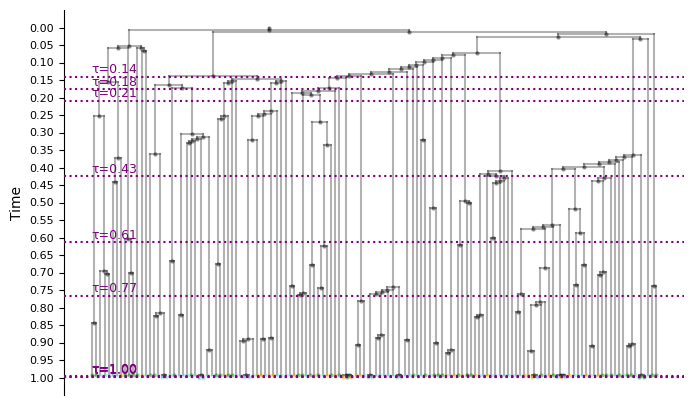

In [14]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_times=diff_times)

In [10]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [11]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')

In [12]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9933550209600294 0.9999999999999999


In [13]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [14]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [15]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['length']
        
        excess = dist - 1.0
        T[parent][leaf]['length'] = max(edge_length - excess, 0)  # avoid negative lengths

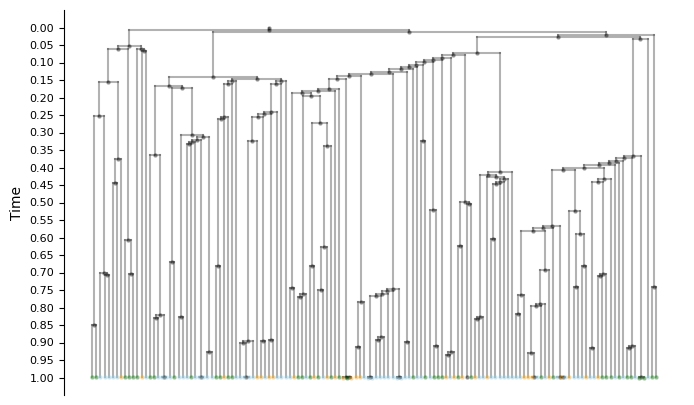

In [16]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [17]:
import networkx as nx

def enforce_min_edge_length(G, root, min_length):
    """
    Adjust node times so that every edge satisfies

        T[parent] - T[child] >= min_length

    Leaves are kept fixed.
    Internal nodes are moved upward only when necessary.

    Updates:
        node['T']
        edge['length']

    Parameters
    ----------
    G : nx.DiGraph
        Rooted tree with parent -> child edges.
    root : node
        Root node.
    min_length : float
        Minimum allowed edge length.

    Returns
    -------
    nx.DiGraph
        Modified copy of G.
    """

    H = G.copy()

    # Postorder = children before parent
    for u in nx.dfs_postorder_nodes(H, root):

        children = list(H.successors(u))

        # leaf: fixed
        if not children:
            continue

        required_time = max(
            H.nodes[v]["T"] + min_length
            for v in children
        )

        # move parent upward only if necessary
        if H.nodes[u]["T"] < required_time:
            H.nodes[u]["T"] = required_time

    # recompute edge lengths
    for u, v in H.edges():
        H.edges[u, v]["length"] = (
            H.nodes[u]["T"] - H.nodes[v]["T"]
        )

    return H

In [18]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

In [19]:
T = enforce_min_edge_length(T, root=T.graph['root'], min_length=0.01)

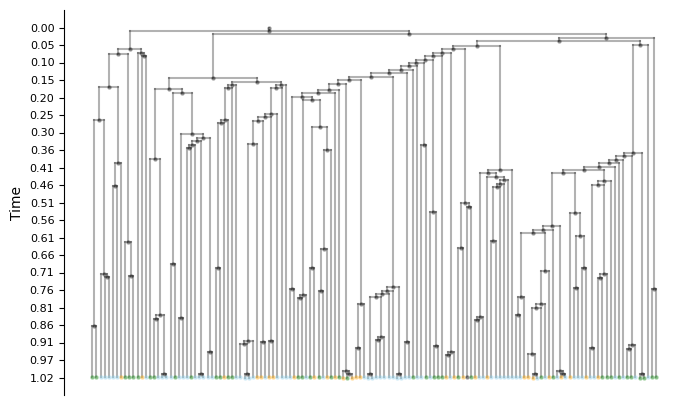

In [20]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [21]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')

In [22]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

1.0164562018034675 1.0165562018034677


In [23]:
EPS = 1e-4
scale = (1 - EPS) / max_dist  # scale to make the min leaf at 1

In [24]:
scale

0.9836150703975658

In [25]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [26]:
scale

0.9836150703975658

In [27]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

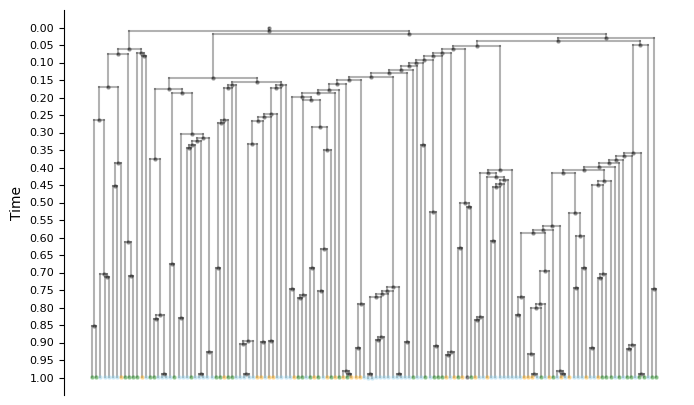

In [28]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [29]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {'Somite': 40, 'NeuralTube': 69, 'NMPs': 28, 'PCGLC': 1})

In [30]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False, 'T': 1}, 1: {'name': '', 'dist': 0.0066449770759561275, 'is_leaf': False, 'T': 0.9901638492960243}, 2: {'name': 'node_232', 'dist': 0.046374793170274466, 'is_leaf': False, 'T': 0.9372031077664625}, 3: {'name': 'node_238', 'dist': 0.006644976998620287, 'is_leaf': False, 'T': 0.924641250253859}, 4: {'name': 'node_244', 'dist': 0.09508556807828979, 'is_leaf': False, 'T': 0.8304974215057395}, 5: {'name': 'node_250', 'dist': 0.0967763410451998, 'is_leaf': False, 'T': 0.7346795654171339}, 6: {'name': 'node_256', 'dist': 0.5932419640265092, 'is_leaf': False, 'T': 0.14731314382174576}, 7: {'name': 'CATAAGCAGGCACTAG-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero', 'T': 0.00019836042038268165}, 8: {'name': 'CGCATAAGTAATCAGA-1', 'dist': 0.14858640166270679, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteSclero', 'T': 0.000

In [31]:
leaf_edge_length = 0
total_edge_length = 0

for u, v in T.edges():
    if len(list(T.successors(v))) == 0:  # v is a leaf
        leaf_edge_length += T.edges[u, v]['length']
    total_edge_length += T.edges[u, v]['length']

print(leaf_edge_length / total_edge_length)

0.6626910737488335


In [32]:
state_dict = {
    'MP': 0,
    'NMSTD': 1,
    'NMSD': 2,
    'NMS': 3,
    'NS': 4,
    'PGCLC': 5,
    'PCGLC': 5,
    'Endothelial': 6,
    'Endoderm': 7,
    'NMPs': 8,
    'Somite': 9,
    'NeuralTube': 10
}

In [33]:
for node, d in T.nodes(data=True):
    if 'state' in d:
        d['state'] = state_dict[d['state']]

In [34]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {9: 40, 10: 69, 8: 28, 5: 1})

In [35]:
from scipy.special import logsumexp
import networkx as nx
import numpy as np
from math import log, ceil, floor

In [42]:
def calculate_Us(
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_rates: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_epochs: list = None,
):
    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t
    num_steps = len(transition_epochs)

    U = np.zeros((num_steps, num_states))
    flow_U = np.zeros((num_steps, num_states))
    Cs = np.zeros((num_steps, num_states))
    total_rates = birth_rates + death_rates + transition_rates.sum(axis=1)
    rs = np.sqrt(total_rates * total_rates - 4 * birth_rates * death_rates)

    U[0, :] = 1.0 - sampling_rate

    numerator = 2 * birth_rates * U[0, :] - (total_rates - rs)
    denominator = 2 * birth_rates * U[0, :] - (total_rates + rs)

    Cs[0, :] = numerator / denominator

    for n in range(1, num_steps):

        prev_time, _ = transition_epochs[n - 1]
        time, transition_edges = transition_epochs[n]

        t = time - delta_t
        
        flow_U[n, :] = (total_rates + rs) / (2 * birth_rates) - \
            rs / (birth_rates * (1 - Cs[n - 1, :] * np.exp(-rs * (t - prev_time))))

        # print(f"n={n}, flow_U[n, :]={flow_U[n, :]} {(total_rates * rs) / (2 * birth_rates)}")


        for s in range(num_states):

            next_transition_sum = 0 

            for u, v in transition_edges:
                if u == s:
                    next_transition_sum += transition_rates[u, v] * delta_t * flow_U[n, v]
            
            # print(f"n={n}, s={s}, flow_U[n, s]={flow_U[n, s]}, next_transition_sum={next_transition_sum}")
            
            U[n, s] = (
                (1.0 - total_rates[s] * delta_t)
                * flow_U[n, s]
                + birth_rates[s]
                * delta_t
                * flow_U[n, s] ** 2
                + death_rates[s] * delta_t
                + next_transition_sum
            )
        
        numerator = 2 * birth_rates * U[n, :] - (total_rates - rs)
        denominator = 2 * birth_rates * U[n, :] - (total_rates + rs)

        Cs[n, :] = numerator / denominator

    return U, flow_U, Cs

In [54]:
from math import log, exp, ceil, floor

from scipy.special import logsumexp

def calculate_log_likelihood_ctmc(
    T: nx.DiGraph,
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    transition_rates: np.ndarray,
    sampling_rate: float,
    flow_U: np.ndarray,
    Cs: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_epochs: list = None,
):
    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t
    num_steps = len(transition_epochs)

    total_rates = (
        birth_rates
        + death_rates
        + transition_rates.sum(axis=1)
    )
    rs = np.sqrt(total_rates * total_rates - 4 * birth_rates * death_rates)

    ####################################################################
    # Postorder edge list
    ####################################################################

    postorder_edges = []

    for parent in nx.dfs_postorder_nodes(T):
        for child in T.successors(parent):
            postorder_edges.append((parent, child))

    edge_to_idx = {
        edge: idx
        for idx, edge in enumerate(postorder_edges)
    }
    num_edges = len(postorder_edges)

    LL = np.full((num_edges, num_states), -np.inf)

    ####################################################################
    # Process edges bottom-up
    ####################################################################

    for edge_idx, (u, v) in enumerate(postorder_edges):

        parent_time = T.nodes[u]["T"]
        child_time = T.nodes[v]["T"]

        children = list(T.successors(v))

        if len(children) == 0:

            child_state = T.nodes[v]["state"]

            boundary_condition = np.full(num_states, -np.inf)
            boundary_condition[child_state] = np.log(sampling_rate)
        
        elif len(children) == 2:

            left_child, right_child = children

            left_edge_idx = edge_to_idx[(v, left_child)]
            right_edge_idx = edge_to_idx[(v, right_child)]

            boundary_condition = (
                    np.log(birth_rates)
                    + LL[left_edge_idx, :]
                    + LL[right_edge_idx, :]
                )
        
        else:
            raise ValueError(f"Node {v} has {len(children)} children, expected 0 or 2.")


        previous_LL = boundary_condition.copy()
        previous_time = child_time
        closest_n = 0

        for n in range(1, num_steps):

            time, transition_edges = transition_epochs[n]

            epoch_start_time = time
            epoch_end_time = time - delta_t

            t_s = min(epoch_start_time, parent_time)
            t_e = max(epoch_end_time, child_time)

            if parent_time > epoch_start_time:
                closest_n = n

            if t_s > t_e:
                
                if previous_time < t_e:
                    previous_LL += -rs * (t_e - previous_time) + \
                                2 * (np.log(1 - Cs[n - 1, :] * np.exp(-rs * (previous_time - transition_epochs[n - 1][0]))) - \
                                     np.log(1 - Cs[n - 1, :] * np.exp(-rs * (t_e - transition_epochs[n - 1][0]))))

                dt = t_s - t_e
    
                current = np.full(num_states, -np.inf)

                A = (
                    1.0
                    - total_rates * dt
                    + 2.0
                    * birth_rates
                    * flow_U[n, :]
                    * dt
                )

                for s in range(num_states):

                    terms = []

                    if A[s] > 0:
                        terms.append(
                            np.log(A[s]) + previous_LL[s]
                        )

                    for state_u, state_v in transition_edges:
                        if state_u != s:
                            continue

                        q = transition_rates[s, state_v]

                        if q > 0:
                            terms.append(
                                np.log(q * dt)
                                + previous_LL[state_v]
                            )

                    current[s] = logsumexp(terms)

                previous_LL = current
                previous_time = t_s
        

        if parent_time > previous_time:
            n = closest_n
            previous_LL += -rs * (parent_time - previous_time) + \
                2 * (np.log(1 - Cs[n, :] * np.exp(-rs * (previous_time - transition_epochs[n][0]))) - \
                     np.log(1 - Cs[n, :] * np.exp(-rs * (parent_time - transition_epochs[n][0]))))

        # print(f"Edge {edge_idx} ({u}->{v}), parent_time={parent_time}, child_time={child_time}, LL={previous_LL}")
        LL[edge_idx, :] = previous_LL

    ####################################################################
    # Root likelihood
    ####################################################################

    root = next(
        n for n in T.nodes
        if T.in_degree(n) == 0
    )

    root_children = list(T.successors(root))

    if len(root_children) != 1:
        raise ValueError(
            "Expected a dummy root with one child."
        )

    root_edge = edge_to_idx[(root, root_children[0])]

    print("LL at root edge:", root_edge, LL[root_edge])

    root_loglikelihood = LL[root_edge, 0]

    return root_loglikelihood, LL

In [ ]:
U, flow_U, Cs = calculate_Us(
    birth_rates=np.array([5.0] * 11),
    death_rates=np.array([2.0] * 11),
    sampling_rate=0.5,
    transition_rates=np.array([
        [0, 2.0, 0], 
        [0, 0, 2.0], 
        [0, 0, 0]]),
    one_by_delta_t=1000,
    transition_epochs=[(0, []), (0.05, [(0, 1), (1, 2)]), (0.1, [(0, 1), (1, 2)])]
)

l, LL = calculate_log_likelihood_ctmc(
    T=T,
    birth_rates=np.array([5.0] * 11),
    death_rates=np.array([2.0] * 11),
    transition_rates=np.array([[2.0] * 11] * 11),
    sampling_rate=0.5,
    flow_U=flow_U,
    Cs=Cs,
    one_by_delta_t=1000,
    transition_epochs=[(0, []), (0.005, [(0, 1), (1, 2)]), (0.01, [(0, 1), (1, 2)])]
)

ValueError: operands could not be broadcast together with shapes (11,) (3,) 

In [44]:
types = np.arange(11)

transition_maps = [
    (0, [1, 5]),
    (1, [2, 6]),
    (2, [3, 7]),
    (3, [4, 8]),
    (4, [9, 10])
]

In [51]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

# MAX_DEATH = 1.0
MAX_BIRTH = 50.0
MAX_TRANSITION = 25.0
COUNT = 0


def unpack_params(theta, epoch_times):

    k = 0

    ####################################################
    # death rates
    ####################################################

    # death = np.zeros(len(types))

    # for i in range(len(types)):
    #     death[i] = MAX_DEATH * sigmoid(theta[k])
    #     k += 1

    death = np.array([0.0] * len(types))

    ####################################################
    # birth rates
    ####################################################

    birth = np.zeros(len(types))

    for i in range(len(types)):
        birth[i] = (
            death[i]
            + (MAX_BIRTH - death[i]) * sigmoid(theta[k])
        )
        k += 1

    ####################################################
    # transition rates
    ####################################################

    Q = np.zeros((len(types), len(types)))

    type_to_idx = {
        t: i
        for i, t in enumerate(types)
    }

    for src, transition_to in transition_maps:

        i = type_to_idx[src]

        for dst in transition_to:

            j = type_to_idx[dst]

            Q[i, j] = (
                MAX_TRANSITION
                * sigmoid(theta[k])
            )

            k += 1
    
    taus = sorted([0.0001 * i for i in range(1, 11)] + epoch_times)

    # taus =  + theta[3:].tolist()  # [0.01 * i + 0.003 for i in range(8)]

    transition_epochs = [(0.0, [])]

    for tau in taus:
        transition_epochs.append(
            (tau, [(0,1), (1,2)])
        )

    return birth, death, Q, transition_epochs


def pack_initial():

    params = []

    # # death parameters
    # params.extend([0.0] * len(types))

    # birth parameters
    params.extend([0.0] * len(types))

    # transition parameters
    for _, transition_to in transition_maps:
        params.extend([0.0] * len(transition_to))

    return np.array(params)


def neg_log_likelihood(theta, trees, epoch_times, sampling_rate=0.5):

    birth, death, Q, transition_epochs = unpack_params(theta, epoch_times)

    U, flow_U, Cs = calculate_Us(
        birth_rates=birth,
        death_rates=death,
        sampling_rate=sampling_rate,
        transition_rates=Q,
        one_by_delta_t=1000,
        transition_epochs=transition_epochs
    )

    total_nll = 0.0

    for tree in trees:

        ll, _ = calculate_log_likelihood_ctmc(
            T=tree,
            birth_rates=birth,
            death_rates=death,
            transition_rates=Q,
            flow_U=flow_U,
            Cs=Cs,
            sampling_rate=sampling_rate,
            one_by_delta_t=1000,
            transition_epochs=transition_epochs,
        )

        total_nll -= ll

    print(
        f"NLL={total_nll:.6f}",
        f"birth={birth}",
        f"transition=[{Q[0,1]}, {Q[1,2]}]",
        f"taus={[tau for tau, _ in transition_epochs]}"
    )

    # write_iteration(birth, death, Q, total_nll)
    # print("WROTE TO FILE")

    return total_nll




def find_params(trees, epoch_times, sampling_rate=0.5):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, epoch_times, sampling_rate),
        method="L-BFGS-B",
        options={
            "disp": True,
            "maxiter": 500,
        },
    )

    birth, death, Q, transition_epochs = unpack_params(result.x, epoch_times)


    print("\nOptimization finished")
    print("Success:", result.success)
    print("Message:", result.message)
    print("Log-likelihood:", -result.fun)
    print("Birth rates:", birth)
    print("Death rates:", death)
    print("Transition rates:")
    print(Q)


    return birth, death, Q, transition_epochs, result

import pandas as pd
import os

CSV_DIR = "../outputs/tls-closed-form/params"

def write_iteration(birth, death, Q, transition_epochs, nll):

    global COUNT

    COUNT += 1

    os.makedirs(CSV_DIR + f"/{COUNT}", exist_ok=True)

    with open(f"{CSV_DIR}/{COUNT}/birth_rates.csv", "w") as f:
        for i, x in enumerate(birth):
            f.write(f"{i},{x}\n")

    with open(f"{CSV_DIR}/{COUNT}/death_rates.csv", "w") as f:
        for i, x in enumerate(death):
            f.write(f"{i},{x}\n")

    with open(f"{CSV_DIR}/{COUNT}/transition_rates.csv", "w") as f:
        for i in range(Q.shape[0]):
            for j in range(Q.shape[1]):
                if Q[i, j] > 0:
                    f.write(f"{i},{j},{Q[i, j]}\n")
    
    with open(f"{CSV_DIR}/{COUNT}/transition_epochs.csv", "w") as f:
        for tau, transitions in transition_epochs:
            for i, j in transitions:
                f.write(f"{tau},{i},{j}\n")
    
    with open(f"{CSV_DIR}/{COUNT}/nll.txt", "w") as f:
        f.write(f"{nll}\n")
    
    print(f"Wrote iteration {COUNT} to {CSV_DIR}/{COUNT}/")

In [52]:
epoch_times = [i * 0.1 for i in range(10)]

find_params([T], epoch_times=epoch_times, sampling_rate=0.5)

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_30615/1080337861.py:147: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(


LL at root edge: 274 [-inf -inf -inf -inf -inf -inf -inf -inf -inf -inf -inf]
NLL=inf birth=[25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25.] transition=[12.5, 12.5] taus=[0.0, 0.0, 0.0001, 0.0002, 0.00030000000000000003, 0.0004, 0.0005, 0.0006000000000000001, 0.0007, 0.0008, 0.0009000000000000001, 0.001, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9]
LL at root edge: 274 [-inf -inf -inf -inf -inf -inf -inf -inf -inf -inf -inf]
NLL=inf birth=[25.00000012 25.         25.         25.         25.         25.
 25.         25.         25.         25.         25.        ] transition=[12.5, 12.5] taus=[0.0, 0.0, 0.0001, 0.0002, 0.00030000000000000003, 0.0004, 0.0005, 0.0006000000000000001, 0.0007, 0.0008, 0.0009000000000000001, 0.001, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9]
LL at root edge: 274 [-inf -inf -inf -inf -inf -inf -inf -inf -inf -inf -inf]
NLL=inf birth=[25.         25.00000012 25.         25

KeyboardInterrupt: 

In [51]:
ts = [t for t in data]

In [52]:
Ts = [ete_to_nx(t) for t in ts]

In [53]:
from dataprocessor import export_tree

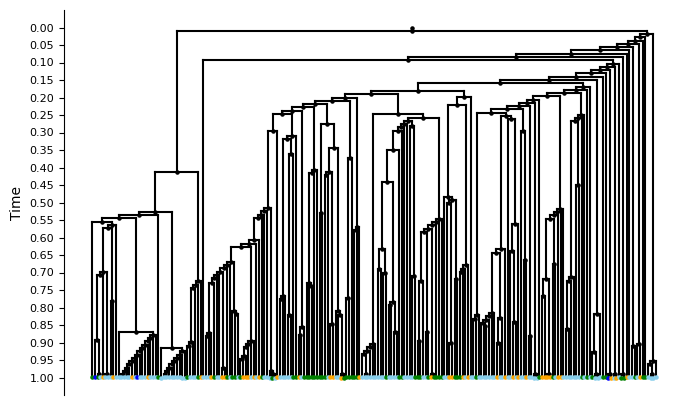

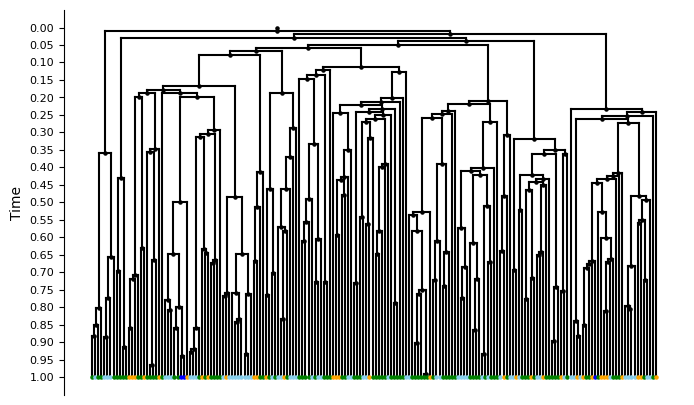

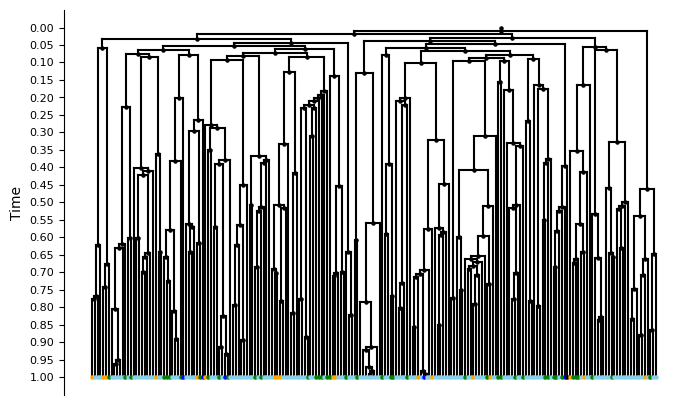

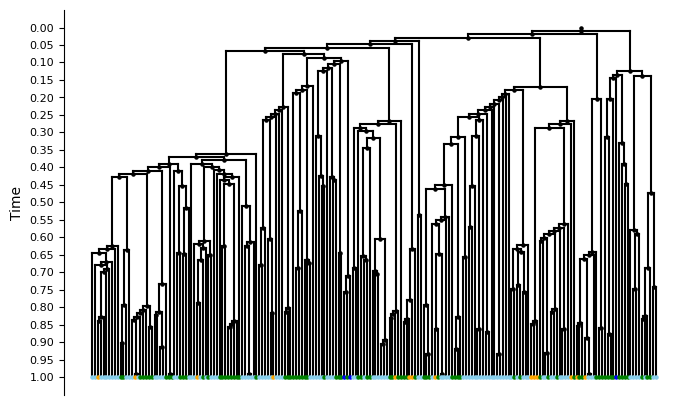

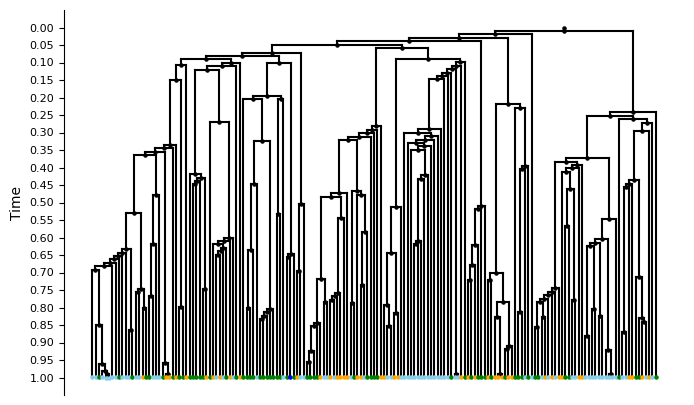

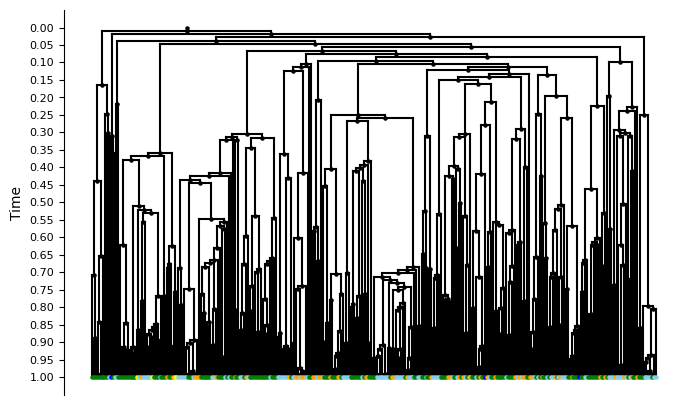

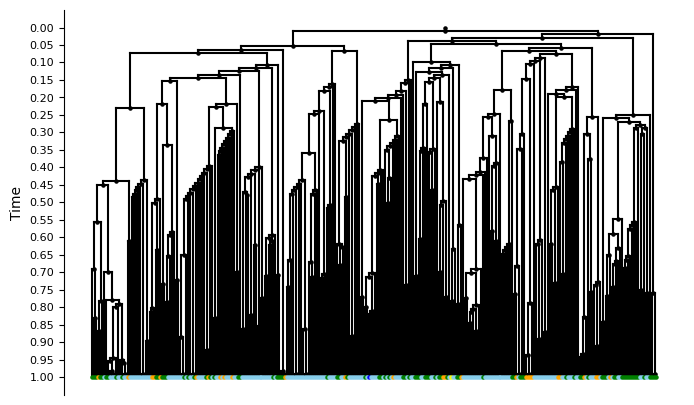

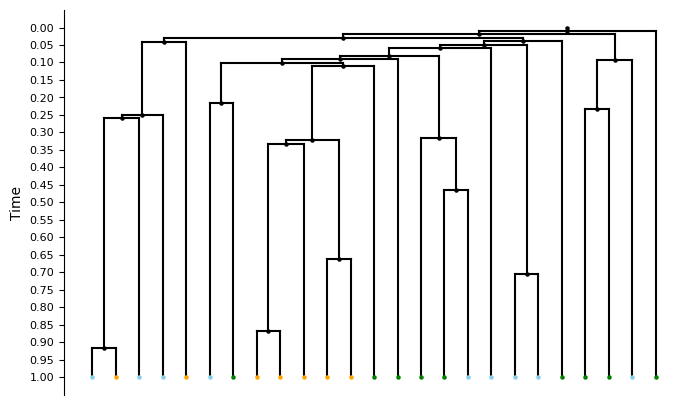

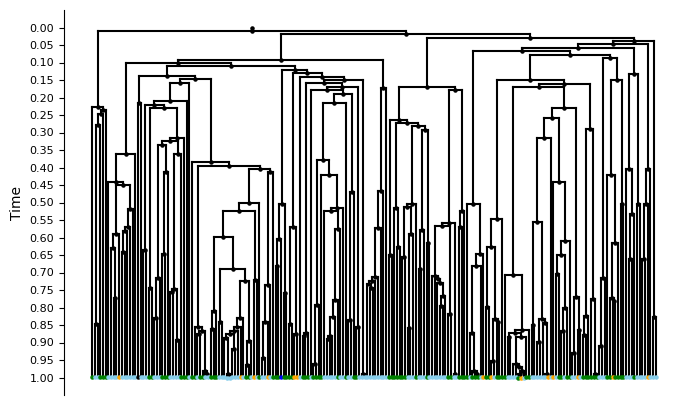

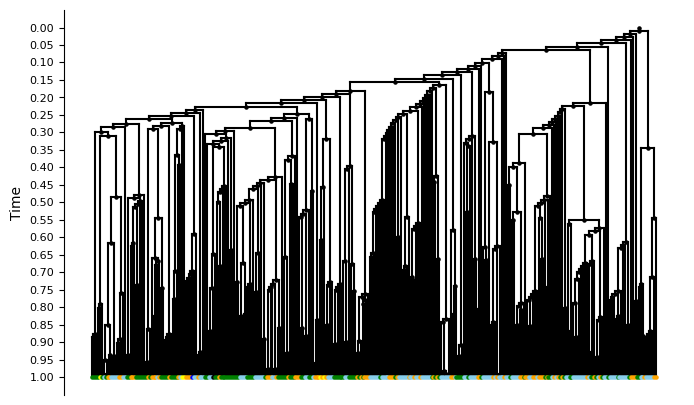

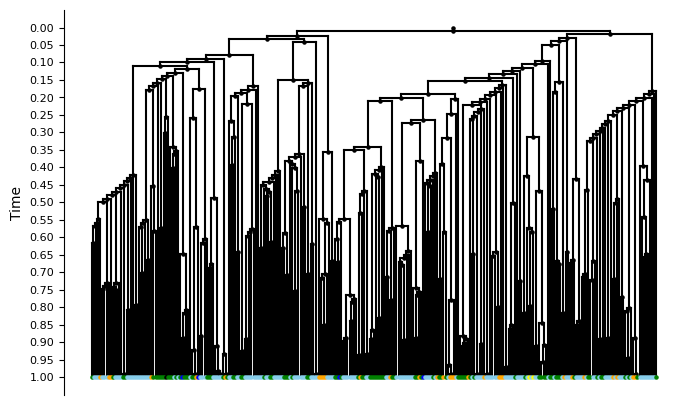

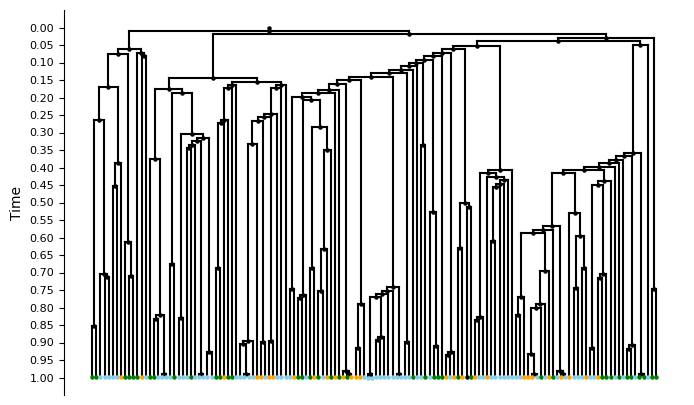

In [54]:
for i in range(len(Ts)):
    leaves = [n for n, d in Ts[i].out_degree() if d == 0]
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(Ts[i], source=Ts[i].graph['root'], target=leaf, weight='length')

    min_dist = min(distances.values())
    max_dist = max(distances.values())
    EPS = 1e-4
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

    for u, v, d in Ts[i].edges(data=True):
        d['length'] *= scale
    for leaf in leaves:
        dist = nx.shortest_path_length(Ts[i], source=Ts[i].graph['root'], target=leaf, weight='length')
        
        if dist > 1.0:
            parent = list(Ts[i].predecessors(leaf))[0]
            
            edge_length = Ts[i][parent][leaf]['length']
            
            excess = dist - 1.0
            Ts[i][parent][leaf]['length'] = max(edge_length - excess, 0)  # avoid negative lengths
    
    Ts[i] = add_node_times(Ts[i], root=Ts[i].graph['root'])
    Ts[i] = enforce_min_edge_length(Ts[i], root=Ts[i].graph['root'], min_length=0.01)

    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(Ts[i], source=Ts[i].graph['root'], target=leaf, weight='length')

    min_dist = min(distances.values())
    max_dist = max(distances.values())
    EPS = 1e-4
    scale = (1 - EPS) / max_dist  # scale to make the min leaf at 1

    for u, v, d in Ts[i].edges(data=True):
        d['length'] *= scale

    Ts[i] = add_node_times(Ts[i], root=Ts[i].graph['root'])
    draw_ultrametric_tree(Ts[i], root=Ts[i].graph['root'], add_labels=False)

    for node, d in Ts[i].nodes(data=True):
        if 'state' in d:
            d['state'] = state_dict[d['state']]
    
    export_tree(Ts[i], f"../data/troupe/TLS/processed_data/nodes_{i}.csv", f"../data/troupe/TLS/processed_data/edges_{i}.csv")
    


In [ ]:
global COUNT
COUNT = 0

find_params(Ts[:3])

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_61322/638094749.py:144: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_61322/317694171.py:204: RuntimeWarning: divide by zero encountered in log
  np.log(q * delta_t)


LL at root edge: 426 [-1876.4551886 -1878.755991           -inf          -inf          -inf
          -inf          -inf          -inf          -inf          -inf
          -inf]
LL at root edge: 370 [-1985.95634296 -1992.93265386           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
LL at root edge: 408 [-2322.97541485           -inf           -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
NLL=6185.386946 birth=[25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25.] death=[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Wrote iteration 1 to ../outputs/tls/params/1/
WROTE TO FILE
LL at root edge: 426 [-1876.45518873 -1878.755991             -inf           -inf
           -inf           -inf           -inf           -inf
           -inf           -inf           -inf]
LL at root edge: 370 [-1985.95634313 -1992.93265386           -inf           -inf
